# Crecimiento tumoral: tres modelos para el diámetro

El tamaño de un tumor sólido se mide con calibrador o con imagen: se registra un diámetro característico $d(t)$ en mm y, suponiendo simetría esférica, el volumen es $V = \frac{\pi}{6}d^3$. Comparamos tres modelos clásicos:

| Modelo | Ecuación | Solución |
|---|---|---|
| Lineal | $\dot d = k$ | $d(t) = d_0 + kt$ |
| Exponencial | $\dot d = \lambda d$ | $d(t) = d_0 e^{\lambda t}$ |
| Gompertz | $\dot d = a\,d\ln(K_d/d)$ | $d(t) = K_d\left(d_0/K_d\right)^{e^{-at}}$ |

**Sobre los datos.** En la sección 3 usamos los datos reales de Benzekry et al. (2014): carcinoma pulmonar de Lewis en 20 ratones, con el volumen del tumor medido entre los días 4 y 22. Spoiler: los parámetros "representativos" del enunciado describen tumores que crecen mucho más rápido que los de estos datos, y eso cambia la respuesta a "¿qué modelo reproduce la desaceleración?".

**Contenido**

1. Interpretación biológica.
2. Análisis matemático: equilibrios, máxima velocidad, invariancia y la relación entre tasas.
3. Datos y parámetros: tiempos de duplicación, máxima velocidad y comparación de los tres modelos.
4. Discusión: desaceleración, hipótesis de Norton–Simon y cáncer de mama humano.

## 1. Interpretación biológica

**Lineal, $\dot d = k$.**
(i) El diámetro aumenta los mismos milímetros cada día. Como $V \propto d^3$, el volumen crece como un polinomio cúbico: $\dot V = \frac{\pi}{2} d^2 k$, proporcional a la **superficie** del tumor. Es lo que pasaría si solo se dividieran las células de una capa de grosor fijo en el borde (el "borde proliferativo") mientras el interior está inactivo.
(ii) Hipótesis: la tasa absoluta de crecimiento del diámetro es constante, sin importar el tamaño.
(iii) Plausible en ventanas cortas o en tumores ya grandes con núcleo necrótico, donde solo prolifera la periferia. Para tumores muy pequeños subestima el crecimiento: ahí casi todas las células se dividen.

**Exponencial, $\dot d = \lambda d$.**
(i) Cada célula se divide a una tasa constante, sin limitación de recursos. El número de células, y con él el volumen, crece exponencialmente con tasa $r = 3\lambda$.
(ii) Hipótesis: tasa de crecimiento per cápita constante; recursos (oxígeno, nutrientes, espacio) ilimitados.
(iii) Plausible en etapas muy tempranas (tumores microscópicos o avasculares pequeños), cuando todas las células tienen acceso a nutrientes por difusión.

**Gompertz, $\dot d = a\,d\ln(K_d/d)$.**
(i) La tasa per cápita $a\ln(K_d/d)$ es muy alta cuando el tumor es pequeño y disminuye logarítmicamente conforme crece: cada vez hay menos oxígeno, espacio y vascularización por célula, más células quiescentes o necróticas.
(ii) Hipótesis: la tasa per cápita decrece con el logaritmo del tamaño y se anula en una capacidad de carga $K_d$.
(iii) Plausible durante gran parte del desarrollo de un tumor sólido, especialmente desde la etapa vascularizada en adelante; es el modelo que mejor describe muchas curvas experimentales y clínicas (Laird 1964; Benzekry et al. 2014).

In [1]:
# ============================================================
# Bibliotecas y modelos
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp          # cálculo simbólico, para verificar las derivaciones

plt.rcParams.update({"figure.dpi": 100, "font.size": 11,
                     "axes.grid": True, "grid.alpha": 0.3})


def d_lineal(t, d0, k):
    """Diámetro del modelo lineal: d0 + k t."""
    return d0 + k * t


def d_exponencial(t, d0, lam):
    """Diámetro del modelo exponencial: d0 exp(lam t)."""
    return d0 * np.exp(lam * t)


def d_gompertz(t, d0, a, Kd):
    """Diámetro del modelo de Gompertz: Kd (d0/Kd)^(exp(-a t))."""
    return Kd * (d0 / Kd) ** np.exp(-a * t)


def v_gompertz(d, a, Kd):
    """Velocidad del modelo de Gompertz, dd/dt = a d ln(Kd/d)."""
    return a * d * np.log(Kd / d)

## 2. Análisis matemático

### (i) Equilibrios y estabilidad

Para $\dot d = f(d)$, un equilibrio cumple $f(d^{\ast}) = 0$ y es estable si $f'(d^{\ast}) < 0$.

* **Lineal:** $f(d) = k > 0$ nunca se anula: **no hay equilibrios**; el tumor crece sin límite.
* **Exponencial:** $f(d) = \lambda d$ se anula solo en $d^{\ast} = 0$, con $f'(0) = \lambda > 0$: **inestable**. Cualquier tumor, por pequeño que sea, crece.
* **Gompertz:** $f(d) = a d\ln(K_d/d)$ se anula en $d^{\ast} = K_d$, con $f'(d) = a\left(\ln\frac{K_d}{d} - 1\right)$, así que $f'(K_d) = -a < 0$: **estable**. En $d = 0$ la función no está definida, pero $f(d)\to 0$ cuando $d \to 0^+$; si la extendemos con $f(0) = 0$, el origen es un equilibrio **inestable** y además muy repulsivo, porque $f'(d) \to +\infty$ cuando $d \to 0^+$ (la tasa per cápita es arbitrariamente grande para tumores diminutos, una característica poco realista del modelo).

### (ii) Velocidad máxima en Gompertz

Buscamos el máximo de $f(d) = a d\ln(K_d/d)$:

$$
f'(d) = a\left(\ln\frac{K_d}{d} - 1\right) = 0 \;\Longleftrightarrow\; \ln\frac{K_d}{d} = 1 \;\Longleftrightarrow\; d^{\ast} = \frac{K_d}{e},
$$

y como $f''(d) = -a/d < 0$, es un máximo. La velocidad máxima es $f(K_d/e) = aK_d/e$. Es decir, **el diámetro crece más rápido cuando vale el 37 % de su tamaño final**; es el punto de inflexión de la sigmoide.

### (iii) Invariancia de Gompertz

Si $\dot V = aV\ln(K/V)$ y $d = (6V/\pi)^{1/3}$, entonces $V = \frac{\pi}{6}d^3$ y, por la regla de la cadena, $\dot V = \frac{\pi}{2}d^2\dot d$. Sustituyendo:

$$
\frac{\pi}{2}d^2\,\dot d = a\,\frac{\pi}{6}d^3\,\ln\frac{K}{\frac{\pi}{6}d^3}
\;\Longrightarrow\;
\dot d = \frac{a}{3}\,d\,\ln\frac{(6K/\pi)}{d^3} = \frac{a}{3}\,d\,\ln\left(\frac{K_d}{d}\right)^{3} = a\,d\ln\frac{K_d}{d},
$$

con $K_d = (6K/\pi)^{1/3}$. El factor $1/3$ de la regla de la cadena se cancela con el exponente 3 dentro del logaritmo: **el diámetro obedece Gompertz con la misma tasa $a$**. Más en general, cualquier potencia $V^{p}$ de un proceso de Gompertz es otro proceso de Gompertz con la misma $a$; esta es una propiedad especial del logaritmo.

### (iv) Exponencial en volumen y en diámetro

Si $V = V_0 e^{rt}$, entonces $d = (6V/\pi)^{1/3} = d_0 e^{rt/3}$: el diámetro es exponencial con tasa $\lambda = r/3$. (A diferencia de Gompertz, aquí la tasa **sí** cambia: el exponente 3 sale del logaritmo y no hay nada que lo cancele.)

Verificamos (ii) y (iii) con cálculo simbólico:

In [2]:
d, a, Kd, K, V = sp.symbols("d a K_d K V", positive=True)

# (ii) máximo de f(d) = a d ln(Kd/d)
f = a * d * sp.log(Kd / d)
crit = sp.solve(sp.diff(f, d), d)
print("Punto crítico de f(d):", crit)
print("f'' en el punto crítico:", sp.simplify(sp.diff(f, d, 2).subs(d, crit[0])))
print("Velocidad máxima:", sp.simplify(f.subs(d, crit[0])))

# (iii) invariancia: si V' = a V ln(K/V), calculamos d' con d = (6V/pi)^(1/3)
V_de_d = sp.pi / 6 * d**3                         # volumen en términos del diámetro
dV_dt = a * V_de_d * sp.log(K / V_de_d)           # V' según Gompertz en volumen
dd_dt = dV_dt / sp.diff(V_de_d, d)                # regla de la cadena: d' = V' / (dV/dd)
Kd_de_K = (6 * K / sp.pi) ** sp.Rational(1, 3)
diferencia = sp.simplify(sp.expand_log(dd_dt - a * d * sp.log(Kd_de_K / d), force=True))
print("d' - a d ln(Kd/d) =", diferencia, " (cero: la invariancia se cumple)")

Punto crítico de f(d): [K_d*exp(-1)]
f'' en el punto crítico: -E*a/K_d
Velocidad máxima: K_d*a*exp(-1)
d' - a d ln(Kd/d) = 0  (cero: la invariancia se cumple)


## 3. Datos y parámetros

### Los datos de Benzekry et al. (2014)

Usamos el conjunto de datos de carcinoma pulmonar de Lewis (LLC) implantado de forma subcutánea en 20 ratones (archivo `LLC_sc_CCSB` del repositorio de Zenodo de Benzekry et al., 2014). Cada fila es una medición: el número de ratón (`ID`), el día (`Time`) y el volumen del tumor en mm³ (`Vol`). Una copia está en [`_data/benzekry2014_LLC_sc_CCSB.csv`](https://github.com/uncrayon/biologia-matematica/blob/main/_data/benzekry2014_LLC_sc_CCSB.csv).

Dos detalles de los datos importan para el análisis:

* **No todos los ratones se midieron los mismos días.** Hay 173 mediciones en días entre el 4 y el 22, con huecos (por ejemplo, casi nadie se midió los días 8 a 10).
* **Los ratones salen del estudio a distintos tiempos.** El volumen máximo registrado es de unos 1 500 mm³; lo más probable es que los ratones se retiraran al alcanzar un tamaño límite (un criterio ético habitual). Por eso, al final del estudio solo quedan los tumores que crecían **más lento**, y cualquier promedio por día en esa etapa está sesgado hacia abajo.

Igual que pide el enunciado, convertimos cada volumen a diámetro con $d = (6V/\pi)^{1/3}$ y usamos $t = \text{día} - 4$, de modo que $t = 0$ corresponde al primer día con datos (el único ratón medido ese día tenía justamente $d \approx 4$ mm, el $d_0$ del enunciado).

In [3]:
import pathlib
import pandas as pd   # lectura de tablas (CSV)

# Si el notebook se ejecuta dentro del repositorio, leemos la copia local;
# si no (por ejemplo, en Colab), la descargamos de GitHub.
RUTA_LOCAL = pathlib.Path("../_data/benzekry2014_LLC_sc_CCSB.csv")
URL = ("https://raw.githubusercontent.com/uncrayon/biologia-matematica/main/"
       "_data/benzekry2014_LLC_sc_CCSB.csv")
datos = pd.read_csv(RUTA_LOCAL if RUTA_LOCAL.exists() else URL)

datos["d"] = (6 * datos["Vol"] / np.pi) ** (1 / 3)   # diámetro equivalente (mm)
datos["t"] = datos["Time"] - 4                        # t = 0 en el día 4

print(f"{len(datos)} mediciones de {datos['ID'].nunique()} ratones, días {datos['Time'].min()} a {datos['Time'].max()}")
print(f"Volumen: de {datos['Vol'].min():.0f} a {datos['Vol'].max():.0f} mm^3"
      f"  ->  diámetro: de {datos['d'].min():.1f} a {datos['d'].max():.1f} mm\n")
print(datos.head(8).to_string(index=False))

# ¿Cuántos ratones se midieron cada día, y cuál es la mediana del diámetro?
por_dia = datos.groupby("Time")["d"].agg(["count", "median"])
print("\nRatones medidos y mediana del diámetro por día:")
print(por_dia.T.round(1).to_string())

# Último día con medición de cada ratón: cuándo "sale" del estudio.
ultimo = datos.groupby("ID")["Time"].max()
print("\nÚltimo día medido (número de ratones):", ultimo.value_counts().sort_index().to_dict())

173 mediciones de 20 ratones, días 4 a 22
Volumen: de 14 a 1492 mm^3  ->  diámetro: de 3.0 a 14.2 mm

 ID  Time       Vol         d  t
  1     7   50.0218  4.571446  3
  1    11  309.5190  8.392594  7
  1    12  324.8960  8.529336  8
  1    13  450.8420  9.513535  9
  1    14  572.4510 10.301803 10
  1    15  664.3370 10.825882 11
  1    18 1151.6900 13.005059 14
  1    19 1338.3800 13.672888 15

Ratones medidos y mediana del diámetro por día:
Time     4    5    6     7    8    9    10    11    12    13    14    15    16    17    18    19    20    21    22
count   1.0  2.0  8.0  12.0  4.0  8.0  8.0  20.0  10.0  10.0  19.0  19.0   9.0   9.0  15.0   7.0   5.0   5.0   2.0
median  4.0  4.9  4.8   5.1  5.6  5.8  6.8   7.4   8.5   9.5  10.3  10.8  11.7  12.5  12.5  13.3  13.4  13.0  13.8

Último día medido (número de ratones): {11: 1, 15: 1, 17: 3, 18: 5, 19: 2, 20: 3, 21: 3, 22: 2}


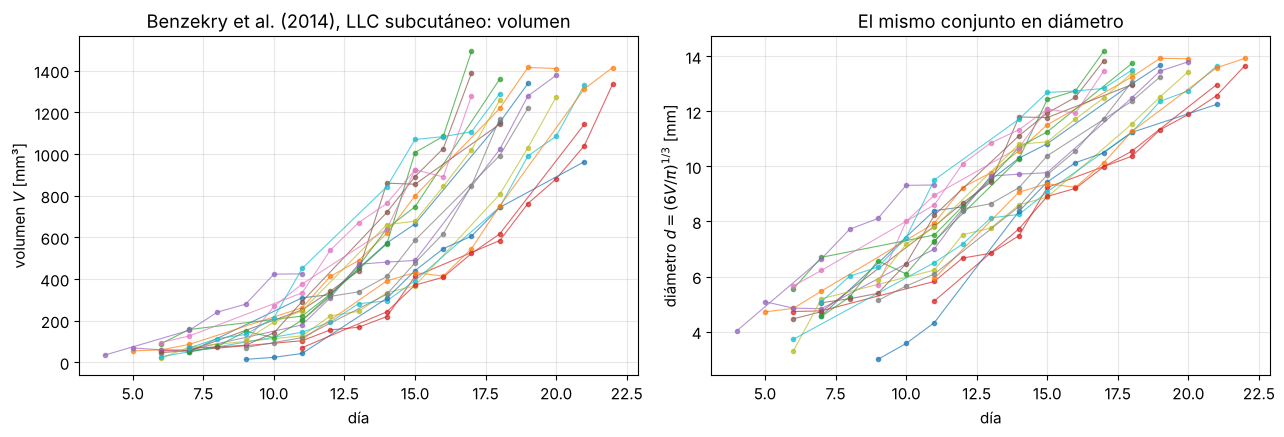

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for raton, grupo in datos.groupby("ID"):
    axs[0].plot(grupo["Time"], grupo["Vol"], "o-", ms=3, lw=0.8, alpha=0.7)
    axs[1].plot(grupo["Time"], grupo["d"], "o-", ms=3, lw=0.8, alpha=0.7)
axs[0].set_ylabel("volumen $V$ [mm³]")
axs[1].set_ylabel(r"diámetro $d = (6V/\pi)^{1/3}$ [mm]")
for ax in axs:
    ax.set_xlabel("día")
axs[0].set_title("Benzekry et al. (2014), LLC subcutáneo: volumen")
axs[1].set_title("El mismo conjunto en diámetro")
plt.tight_layout()
plt.show()

### Cálculos con $K_d = 15$ mm, $a = 0.25$ día⁻¹ y $d_0 = 4$ mm

Despejando el tiempo de la solución de Gompertz: $\ln\frac{d}{K_d} = \ln\frac{d_0}{K_d}\,e^{-at}$, de donde

$$
t(d) = -\frac{1}{a}\ln\!\left(\frac{\ln(d/K_d)}{\ln(d_0/K_d)}\right).
$$

(i) Duplicar el diámetro es llegar a $d = 2d_0 = 8$ mm. (ii) Llegar a 10 mm es $d = 10$. (iii) La velocidad máxima es $aK_d/e$ y ocurre cuando $d = K_d/e$, es decir cuando $\ln(d/K_d) = -1$, en $t = \frac{1}{a}\ln\ln(K_d/d_0)$.

In [5]:
KD_REP, A_REP, D0_REP = 15.0, 0.25, 4.0   # valores representativos del enunciado
Kd_, a_, d0_ = KD_REP, A_REP, D0_REP


def tiempo_para(d_meta, d0=d0_, a=a_, Kd=Kd_):
    """Días que tarda Gompertz en ir de d0 a d_meta (requiere d0 < d_meta < Kd)."""
    return -np.log(np.log(d_meta / Kd) / np.log(d0 / Kd)) / a


t_dup = tiempo_para(2 * d0_)
t_10 = tiempo_para(10.0)
d_max = Kd_ / np.e
v_max = a_ * Kd_ / np.e
t_vmax = tiempo_para(d_max)
print(f"(i)   duplicar el diámetro (4 -> 8 mm):  {t_dup:.2f} días")
print(f"(ii)  llegar a 10 mm:                    {t_10:.2f} días")
print(f"(iii) velocidad máxima = a Kd / e =      {v_max:.3f} mm/día")
print(f"      ocurre cuando d = Kd / e =         {d_max:.2f} mm, en t = {t_vmax:.2f} días")
print(f"\nComparación: la velocidad inicial es a d0 ln(Kd/d0) = {v_gompertz(d0_, a_, Kd_):.3f} mm/día;")
print(f"el tiempo de duplicación del modelo exponencial con la misma tasa inicial sería "
      f"ln 2 / (a ln(Kd/d0)) = {np.log(2) / (a_ * np.log(Kd_ / d0_)):.2f} días.")
print(f"Gompertz tarda más ({t_dup:.2f} días) porque ya está desacelerando.")

(i)   duplicar el diámetro (4 -> 8 mm):  2.97 días
(ii)  llegar a 10 mm:                    4.73 días
(iii) velocidad máxima = a Kd / e =      1.380 mm/día
      ocurre cuando d = Kd / e =         5.52 mm, en t = 1.12 días

Comparación: la velocidad inicial es a d0 ln(Kd/d0) = 1.322 mm/día;
el tiempo de duplicación del modelo exponencial con la misma tasa inicial sería ln 2 / (a ln(Kd/d0)) = 2.10 días.
Gompertz tarda más (2.97 días) porque ya está desacelerando.


### (iv) Los tres modelos durante 30 días, contra los datos

Para que la comparación sea justa elegimos parámetros "comparables": los tres modelos parten de $d_0 = 4$ mm **con la misma velocidad inicial** que Gompertz. Así, $k = a d_0\ln(K_d/d_0)$ (mm/día) y $\lambda = a\ln(K_d/d_0)$ (día⁻¹). Sobre las curvas ponemos los datos reales.

k = 1.322 mm/día,  lambda = 0.330 1/día


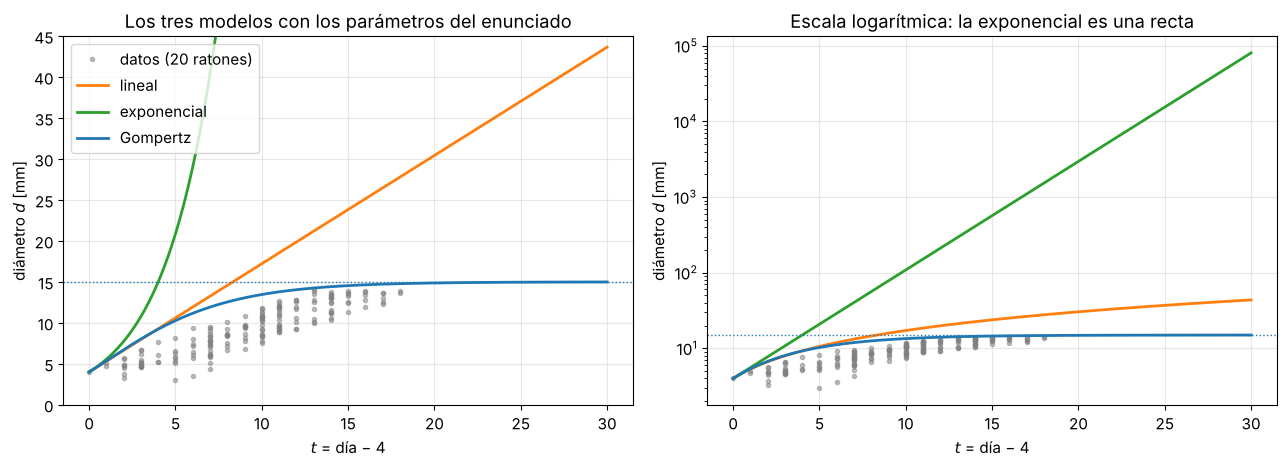

lineal      : error medio =    +7.10 mm, raíz del error cuadrático medio =     7.77 mm
exponencial : error medio =  +192.77 mm, raíz del error cuadrático medio =   338.31 mm
Gompertz    : error medio =    +3.15 mm, raíz del error cuadrático medio =     3.54 mm

Día 11 (t = 7): mediana de los datos = 7.4 mm, Gompertz del enunciado = 11.9 mm


In [6]:
k_ = a_ * d0_ * np.log(Kd_ / d0_)      # misma velocidad inicial (mm/día)
lam_ = a_ * np.log(Kd_ / d0_)          # misma tasa per cápita inicial (1/día)
print(f"k = {k_:.3f} mm/día,  lambda = {lam_:.3f} 1/día")

t = np.linspace(0, 30, 400)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
for ax in axs:
    ax.plot(datos["t"], datos["d"], "o", color="gray", ms=3, alpha=0.5, label="datos (20 ratones)")
    ax.plot(t, d_lineal(t, d0_, k_), "C1", lw=2, label="lineal")
    ax.plot(t, d_exponencial(t, d0_, lam_), "C2", lw=2, label="exponencial")
    ax.plot(t, d_gompertz(t, d0_, a_, Kd_), "C0", lw=2, label="Gompertz")
    ax.axhline(Kd_, color="C0", ls=":", lw=1)
    ax.set_xlabel("$t$ = día − 4")
    ax.set_ylabel("diámetro $d$ [mm]")
axs[0].set_ylim(0, 45)
axs[0].set_title("Los tres modelos con los parámetros del enunciado")
axs[0].legend(loc="upper left")
axs[1].set_yscale("log")
axs[1].set_title("Escala logarítmica: la exponencial es una recta")
plt.tight_layout()
plt.show()

# Error de cada modelo (con los parámetros del enunciado, sin ajustar) en cada medición.
for nombre, curva in [("lineal", d_lineal(datos["t"], d0_, k_)),
                      ("exponencial", d_exponencial(datos["t"], d0_, lam_)),
                      ("Gompertz", d_gompertz(datos["t"], d0_, a_, Kd_))]:
    error = curva - datos["d"]
    print(f"{nombre:12s}: error medio = {error.mean():+8.2f} mm, raíz del error cuadrático medio = {np.sqrt(np.mean(error**2)):8.2f} mm")
print(f"\nDía 11 (t = 7): mediana de los datos = {por_dia.loc[11, 'median']:.1f} mm,"
      f" Gompertz del enunciado = {d_gompertz(7, d0_, a_, Kd_):.1f} mm")

**Los parámetros "representativos" no describen estos datos.** Con $a = 0.25$ día⁻¹, Gompertz predice que el tumor llega a unos 12 mm el día 11; la mediana real ese día es de 7.4 mm. Los tres modelos, con los parámetros del enunciado, crecen **demasiado rápido**: Gompertz sobreestima el diámetro en unos 3 mm en promedio, el lineal en unos 7 mm y el exponencial se dispara. Entre ellos, Gompertz es el que menos se aleja, precisamente porque desacelera, pero desacelera demasiado pronto: con esos parámetros el tumor ya estaría casi en su tamaño final hacia el día 15, mientras que los tumores reales siguen creciendo hasta que se retira al ratón.

Las respuestas (i)–(iii) son correctas para el modelo con esos parámetros, pero no hay que leerlas como predicciones para estos tumores: con los datos, el diámetro mediano pasa de unos 4–5 mm (días 4–7) a unos 8.5 mm el día 12: duplicarlo toma más de una semana, no 3 días.

d entre  3 y  5 mm:   9 pares, velocidad mediana = 0.26 mm/día
d entre  5 y  7 mm:  30 pares, velocidad mediana = 0.72 mm/día
d entre  7 y  9 mm:  30 pares, velocidad mediana = 0.90 mm/día
d entre  9 y 11 mm:  38 pares, velocidad mediana = 0.76 mm/día
d entre 11 y 13 mm:  36 pares, velocidad mediana = 0.79 mm/día
d entre 13 y 15 mm:  10 pares, velocidad mediana = 0.67 mm/día


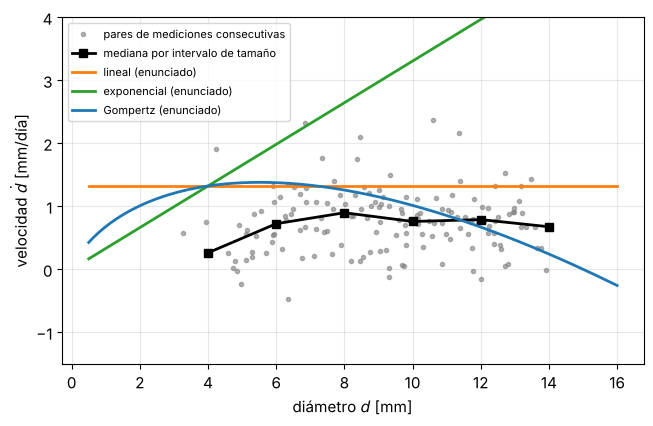

In [7]:
# Velocidad de crecimiento contra tamaño: la forma más directa de ver si hay
# desaceleración. Para cada ratón usamos pares de mediciones consecutivas.
pares = []
for raton, g in datos.sort_values("Time").groupby("ID"):
    dt = np.diff(g["Time"].to_numpy())
    dd_ = np.diff(g["d"].to_numpy())
    dm = (g["d"].to_numpy()[1:] + g["d"].to_numpy()[:-1]) / 2
    pares.append(np.column_stack([dm, dd_ / dt]))
pares = np.vstack(pares)            # columnas: diámetro medio, velocidad (mm/día)

# Mediana de la velocidad por intervalos de tamaño (para ver la tendencia entre el ruido).
bordes = np.arange(3, 16, 2)
centros, med_vel = [], []
for lo, hi in zip(bordes[:-1], bordes[1:]):
    sel = (pares[:, 0] >= lo) & (pares[:, 0] < hi)
    if sel.sum() >= 5:
        centros.append((lo + hi) / 2)
        med_vel.append(np.median(pares[sel, 1]))
        print(f"d entre {lo:2d} y {hi:2d} mm: {sel.sum():3d} pares, velocidad mediana = {med_vel[-1]:.2f} mm/día")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(pares[:, 0], pares[:, 1], ".", color="gray", alpha=0.6, label="pares de mediciones consecutivas")
ax.plot(centros, med_vel, "ks-", lw=2, label="mediana por intervalo de tamaño")
dd = np.linspace(0.5, 16, 300)
ax.plot(dd, np.full_like(dd, k_), "C1", lw=2, label="lineal (enunciado)")
ax.plot(dd, lam_ * dd, "C2", lw=2, label="exponencial (enunciado)")
ax.plot(dd, v_gompertz(dd, a_, Kd_), "C0", lw=2, label="Gompertz (enunciado)")
ax.set_xlabel("diámetro $d$ [mm]")
ax.set_ylabel("velocidad $\\dot d$ [mm/día]")
ax.set_ylim(-1.5, 4)
ax.legend(fontsize=8)
plt.show()

### Extra: ¿qué dicen los datos si sí ajustamos?

El enunciado pide usar los parámetros dados, no ajustarlos, y eso es lo que hicimos arriba. Pero como esos parámetros no describen los datos, la pregunta "¿cuál modelo reproduce la desaceleración?" queda mejor contestada si dejamos que cada modelo elija sus mejores parámetros. Ajustamos los tres por mínimos cuadrados al diámetro de todas las mediciones juntas y los comparamos con el **criterio de información de Akaike** (AIC), que premia el buen ajuste pero penaliza tener más parámetros: menor AIC es mejor, y diferencias menores que 2 se consideran poco importantes.

(Simplificaciones: tratamos todas las mediciones como independientes y con los mismos parámetros para todos los ratones. Un análisis más fino usaría modelos de efectos mixtos, que es lo que hacen Benzekry et al.)

lineal      : d0 = 3.287 ± 0.229, k = 0.635 ± 0.022
              raíz del error cuadrático medio = 1.24 mm, AIC = 78.5
exponencial : d0 = 4.787 ± 0.160, lambda = 0.066 ± 0.003
              raíz del error cuadrático medio = 1.34 mm, AIC = 105.0
Gompertz    : d0 = 3.286 ± 0.306, a = 0.089 ± 0.017, Kd = 20.715 ± 3.015
              raíz del error cuadrático medio = 1.22 mm, AIC = 76.0


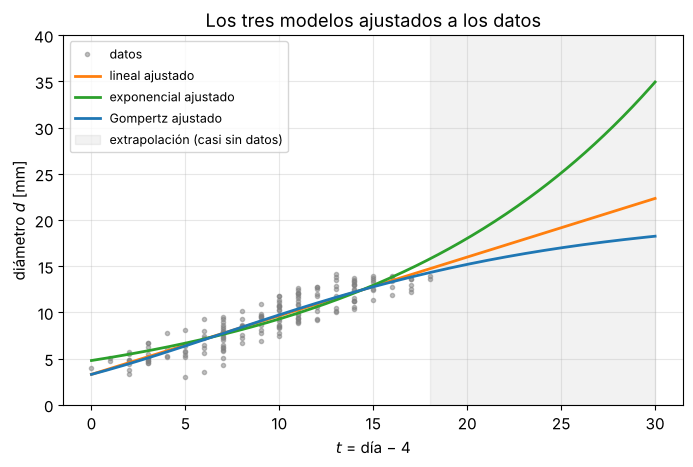

In [8]:
from scipy.optimize import curve_fit

t_obs, d_obs = datos["t"].to_numpy(), datos["d"].to_numpy()
ajustes = {
    "lineal": (d_lineal, [4, 0.5], ["d0", "k"]),
    "exponencial": (d_exponencial, [4, 0.1], ["d0", "lambda"]),
    "Gompertz": (lambda t, d0, a, Kd: d_gompertz(t, d0, a, Kd), [4, 0.1, 20], ["d0", "a", "Kd"]),
}
parametros = {}
for nombre, (f, p0, nombres) in ajustes.items():
    p, cov = curve_fit(f, t_obs, d_obs, p0=p0, maxfev=20000)
    ee = np.sqrt(np.diag(cov))
    rss = np.sum((d_obs - f(t_obs, *p)) ** 2)
    n = len(d_obs)
    aic = n * np.log(rss / n) + 2 * len(p)
    parametros[nombre] = p
    texto = ", ".join(f"{nm} = {v:.3f} ± {e:.3f}" for nm, v, e in zip(nombres, p, ee))
    print(f"{nombre:12s}: {texto}")
    print(f"{'':12s}  raíz del error cuadrático medio = {np.sqrt(rss / n):.2f} mm, AIC = {aic:.1f}")

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(t_obs, d_obs, "o", color="gray", ms=3, alpha=0.5, label="datos")
t = np.linspace(0, 30, 300)
for (nombre, (f, _, _)), c in zip(ajustes.items(), ["C1", "C2", "C0"]):
    ax.plot(t, f(t, *parametros[nombre]), c, lw=2, label=f"{nombre} ajustado")
ax.axvspan(18, 30, color="gray", alpha=0.1, label="extrapolación (casi sin datos)")
ax.set_ylim(0, 40)
ax.set_xlabel("$t$ = día − 4")
ax.set_ylabel("diámetro $d$ [mm]")
ax.set_title("Los tres modelos ajustados a los datos")
ax.legend(fontsize=9)
plt.show()

**¿Cuál reproduce la desaceleración?** Con los datos reales la respuesta tiene matices:

* **El exponencial queda descartado:** predice que la velocidad aumenta con el tamaño y es el que peor ajusta, con un AIC mucho mayor que los otros dos.
* **Gompertz ajustado es el mejor**, pero por poco: su tasa ajustada es $a \approx 0.09$ día⁻¹ (no 0.25) y su capacidad de carga $K_d \approx 21$ mm (no 15), muy incierta porque ningún tumor se acercó a ese tamaño. El modelo lineal, que no desacelera, queda casi empatado en el intervalo observado.
* **Dentro del periodo observado, la desaceleración en diámetro es modesta:** la velocidad mediana se mantiene entre 0.7 y 0.9 mm/día para tumores de 5 a 15 mm. Lo que sí se ve es lo contrario al inicio: los tumores más pequeños (menos de 5 mm) crecen más lento, alrededor de 0.3 mm/día, probablemente porque el implante tarda en establecerse; ninguno de los tres modelos contempla esa fase. Un diámetro que crece casi linealmente equivale a un volumen que crece como $t^3$: su tasa per cápita, $3k/(d_0 + kt)$, sí disminuye con el tiempo, así que en **volumen** la desaceleración respecto a un crecimiento exponencial es clara.
* **Por qué no vemos la meseta:** los ratones se retiran del estudio alrededor de 1 500 mm³ (unos 14 mm de diámetro), antes de que el tumor se acerque a su capacidad de carga. Los datos simplemente no llegan a la zona donde Gompertz y el lineal se separan (la región sombreada de la figura), y por eso el último tramo no permite decidir entre ellos.

La lección general: **un modelo con parámetros "de libro" puede tener la forma correcta y aun así no describir los datos**, y la capacidad de distinguir modelos depende de que los datos cubran la región donde sus predicciones difieren.

## 4. Discusión

**(i) ¿Por qué desaceleran los tumores reales?** Varias razones actúan a la vez:

* **Hipoxia y difusión limitada:** el oxígeno y los nutrientes penetran solo unos 100–200 μm desde un vaso sanguíneo; en un tumor grande las células del centro reciben poco y dejan de dividirse.
* **Necrosis:** las células más lejanas mueren; el núcleo necrótico ocupa volumen sin aportar crecimiento.
* **Limitación vascular:** la angiogénesis no siempre alcanza a irrigar todo el tumor, y los vasos tumorales son desordenados e ineficientes.
* **Presión mecánica y espacio:** el tejido circundante y la presión intersticial frenan la expansión.
* **Respuesta inmune:** linfocitos y macrófagos eliminan células tumorales, más cuanto mayor es el tumor.

Todas tienen el mismo efecto en el modelo: la tasa per cápita disminuye con el tamaño, que es justamente la hipótesis de Gompertz.

**(ii) Hipótesis de Norton–Simon.** Según esta hipótesis, el efecto de un tratamiento es proporcional a la velocidad de crecimiento que tendría el tumor sin tratar a ese tamaño. La respuesta depende de qué "velocidad" usemos:

* Si es la **tasa per cápita** $a\ln(K_d/d)$, que es la que determina qué **fracción** de células se elimina, el tratamiento es más eficaz cuanto **más pequeño** es el tumor: tratar lo antes posible, y no dejar que el tumor residual vuelva a crecer entre ciclos.
* Si es la **velocidad absoluta** del diámetro, $\dot d$, el máximo está en $d = K_d/e \approx 5.5$ mm.

Ojo: el punto de máxima velocidad absoluta **depende de la variable que midamos**. Para el volumen, $\dot V$ es máxima cuando $V = K/e$, es decir cuando $d = K_d\,e^{-1/3} \approx 10.7$ mm, no 5.5 mm. La invariancia de la sección 2 se refiere a la tasa $a$, no al punto de inflexión. La lectura per cápita es la que no depende de esa elección y es la que tiene una interpretación directa como fracción eliminada. Esta línea de razonamiento es la que motivó los esquemas de quimioterapia de "dosis densa" (ciclos más frecuentes).

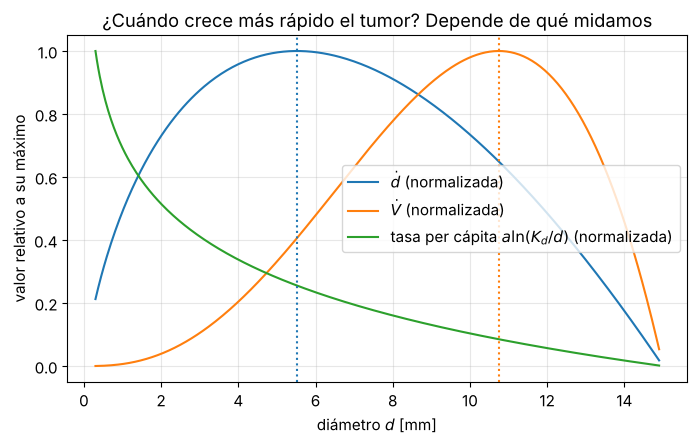

In [9]:
# Velocidad absoluta del diámetro y del volumen, y tasa per cápita, contra el diámetro.
dd = np.linspace(0.3, 14.9, 400)
V_dd = np.pi / 6 * dd**3
K_V = np.pi / 6 * Kd_**3
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(dd, v_gompertz(dd, a_, Kd_) / v_gompertz(Kd_ / np.e, a_, Kd_), label=r"$\dot d$ (normalizada)")
vV = a_ * V_dd * np.log(K_V / V_dd)
ax.plot(dd, vV / vV.max(), label=r"$\dot V$ (normalizada)")
tasa = a_ * np.log(Kd_ / dd)
ax.plot(dd, tasa / tasa.max(), label=r"tasa per cápita $a\ln(K_d/d)$ (normalizada)")
ax.axvline(Kd_ / np.e, color="C0", ls=":")
ax.axvline(Kd_ * np.exp(-1 / 3), color="C1", ls=":")
ax.set_xlabel("diámetro $d$ [mm]")
ax.set_ylabel("valor relativo a su máximo")
ax.set_title("¿Cuándo crece más rápido el tumor? Depende de qué midamos")
ax.legend()
plt.show()

**(iii) Cáncer de mama humano (Spratt, 1993).** Que los diámetros medidos por mamografía en tumores humanos también sigan una dinámica de Gompertz sugiere que:

* La desaceleración **no es un artefacto** de los modelos de ratón: es una propiedad general del crecimiento de tumores sólidos.
* Cuando un tumor se detecta clínicamente (alrededor de 1 cm, unas $10^9$ células) ya pasó buena parte de su historia; la fase de crecimiento per cápita más rápido ocurrió cuando era indetectable. Si se extrapola hacia atrás con un modelo exponencial usando la tasa medida al momento del diagnóstico (que ya es lenta), se **sobreestima** la edad del tumor: en realidad creció mucho más rápido cuando era pequeño. La forma de la curva importa para estimar desde cuándo existe.
* Las tasas per cápita son mayores en tumores pequeños, así que los tumores detectados temprano (por tamizaje) no solo son más pequeños, también podrían ser más sensibles a tratamientos que actúan sobre células en división (en la lógica de Norton–Simon).
* Permite predecir el crecimiento de un tumor a partir de pocas mediciones y comparar tumores con un par de parámetros ($a$, $K_d$).

**Referencias:** Gompertz (1825); Laird (1964), *Br. J. Cancer* 18: 490–497; Norton & Simon (1977), *Cancer* 31: 572–578; Benzekry et al. (2014), *PLoS Comput. Biol.* 10: e1003800; Vaghi et al. (2020), *PLoS Comput. Biol.* 16: e1007178; Spratt (1993), *Cancer* 71: 2013–2019.